# Milestone 3

Continues the M2 notebook. Instead of adding onto the other notebook, instead just gonna run the M2 notebook itself here, the version originally submitted.

In [ ]:
import hashlib
import json
import platform
import random
import urllib.request
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

In [ ]:
# checking versions since numbers can change a bit between versions
# these are the versions colab had when we ran this (same as requirements.txt)
expected_versions = {'pandas': '2.2.3', 'numpy': '2.0.2', 'scikit-learn': '1.6.1'}
current_versions = {'pandas': pd.__version__, 'numpy': np.__version__, 'scikit-learn': sklearn.__version__}

for lib in expected_versions:
  if current_versions[lib] == expected_versions[lib]:
    print(lib, current_versions[lib], 'ok')
  else:
    print(lib, current_versions[lib], 'WARNING: expected', expected_versions[lib])
print('python', platform.python_version())

# setting the seed so anything random gives the same result every run
seed = 42
random.seed(seed)
np.random.seed(seed)

# folder for the tables and figures
results_folder = Path('results')
results_folder.mkdir(exist_ok=True)

pandas 2.2.3 ok
numpy 2.1.3 WARNING: expected 2.0.2
scikit-learn 1.6.1 ok
python 3.13.16


In [ ]:
# making sure the dataset on github is the exact same file we built the baseline on
# if someone changes the csv the numbers wont match anymore, so it stops here
data_url = 'https://raw.githubusercontent.com/tabishghouri/Machine-Learning-Project/main/Datasets/consommation-clients-evenements-pointe.csv'
expected_sha256 = '3cc2b88b8840671770f34cb20f94259c4de405a197b26a80b0f992d37e7d6370'

data_sha256 = hashlib.sha256(urllib.request.urlopen(data_url).read()).hexdigest()
assert data_sha256 == expected_sha256, 'dataset on github changed, numbers will not reproduce'
print('dataset checksum ok')

dataset checksum ok


In [ ]:
# getting the m2 notebook from the commit we submitted for m2
# pinned to that commit so later edits to the m2 notebook cant change m3
m2_commit = '258a12e5aeb49db59b724599ae357c17a2db83dd'
m2_url = ('https://raw.githubusercontent.com/tabishghouri/Machine-Learning-Project/' + m2_commit +
          '/Milestone%202/Predicting_Quebec_Winter_Electricity_Demand_Machine_Learning_Project.ipynb')
urllib.request.urlretrieve(m2_url, 'm2_notebook.ipynb')
print('downloaded m2 notebook, commit', m2_commit[:7])

downloaded m2 notebook, commit 258a12e


In [ ]:
%%capture m2_output
%run -i m2_notebook.ipynb

In [ ]:
# same final check as the end of m2
print(hq.shape)
print(hq.isna().sum().sum(), 'blanks')
print(hq['was_missing'].sum(), 'rows added (missing hours)')
print(hq['spike_fixed'].sum(), 'values replaced (spikes)')
print(hq.duplicated(['substation', 'timestamp_clean']).sum(), 'duplicates')

plt.rcParams['figure.dpi'] = 110

(65661, 34)
0 blanks
1056 rows added (missing hours)
21 values replaced (spikes)
0 duplicates


# Feature Engineering

In [ ]:
# Making Separate copy for ML model
model_df = hq.copy()

# Rows are ordered by substation and time
model_df = model_df.sort_values(['substation', 'timestamp_clean']).reset_index(drop=True)

# Creating lag features
model_df['lag_1h'] = model_df.groupby('substation')['energy_per_client'].shift(1)
model_df['lag_24h'] = model_df.groupby('substation')['energy_per_client'].shift(24)
model_df['lag_168h'] = model_df.groupby('substation')['energy_per_client'].shift(168)

display(model_df[[
    'substation', 'timestamp_clean',
    'energy_per_client', 'lag_1h',
    'lag_24h', 'lag_168h'
]].head(10))

,substation,timestamp_clean,energy_per_client,lag_1h,lag_24h,lag_168h
0,A,2022-01-01 00:00:00-05:00,3.584216,NaN,NaN,NaN
1,A,2022-01-01 01:00:00-05:00,3.477471,3.584216,NaN,NaN
2,A,2022-01-01 02:00:00-05:00,3.230708,3.477471,NaN,NaN
3,A,2022-01-01 03:00:00-05:00,3.077862,3.230708,NaN,NaN
4,A,2022-01-01 04:00:00-05:00,3.281740,3.077862,NaN,NaN
5,A,2022-01-01 05:00:00-05:00,3.965606,3.281740,NaN,NaN
6,A,2022-01-01 06:00:00-05:00,4.608892,3.965606,NaN,NaN
7,A,2022-01-01 07:00:00-05:00,4.589421,4.608892,NaN,NaN
8,A,2022-01-01 08:00:00-05:00,4.686603,4.589421,NaN,NaN
9,A,2022-01-01 09:00:00-05:00,5.253836,4.686603,NaN,NaN


In [ ]:
#Hilo event features

#Hilo challenge active
model_df['is_hilo_event'] = (model_df['challenge_flag'] == 1).astype(int)

#pre/post challenge period
model_df['is_pre_post_event'] = (model_df['pre_post_challenge_flag'] == 1).astype(int)

#CPR challenge types
model_df['is_CPR'] = (model_df['challenge_type'] == 'CPR').astype(int)

#LCPR challenge type
model_df['is_LCPR'] = (model_df['challenge_type'] == 'LCPR').astype(int)

In [ ]:
# mean of the whole day before, smoother than one hour from yesterday
model_df['lag_24h_mean_day'] = model_df.groupby('substation')['energy_per_client'].transform(lambda s: s.shift(24).rolling(24).mean())

# from figure 3 in m2, energy use is pretty flat above ~18 degrees and goes up in a straight-ish line below it
# a straight line on the raw temperature cant do that bend, so heating degrees = how far below 18 it is (0 when warmer)
model_df['heating_degrees'] = np.maximum(0, 18 - model_df['average_outside_temperature'])

# true/false and 0.0/1.0 into 1/0 for the models
model_df['weekend_holiday'] = model_df['weekend_holiday'].astype(int)
model_df['challenge_flag'] = model_df['challenge_flag'].astype(int)
model_df['pre_post_challenge_flag'] = model_df['pre_post_challenge_flag'].astype(int)

# dec, jan, feb so winter can be scored on its own
model_df['is_winter'] = model_df['month'].isin([12, 1, 2])

# get_dummies in the next cell replaces the substation column
# keeping a copy since the benchmarks and plots still need the letter
model_df['substation_name'] = model_df['substation']

In [ ]:
#Converting substation labels into numeric values for linear regression
model_df = pd.get_dummies(model_df, columns=['substation'], prefix='station', dtype=int)

#Display
display(model_df[['station_A', 'station_B', 'station_C']].head())

,station_A,station_B,station_C
0,1,0,0
1,1,0,0
2,1,0,0
3,1,0,0
4,1,0,0


In [ ]:
#Features
allFeatures = [
    'energy_per_client',
    'lag_1h',
    'lag_24h',
    'lag_168h',
    'hour_sin',
    'hour_cos',
    'month_sin',
    'month_cos',
    'average_outside_temperature',
    'average_temperature_setpoint',
    'average_inside_temperature',
    'average_relative_humidity',
    'average_snow_precipitation',
    'average_wind_speed',
    'is_hilo_event',
    'is_pre_post_event',
    'is_CPR',
    'is_LCPR',
    'station_A',
    'station_B',
    'station_C'
]
print(model_df.shape)

print(model_df[allFeatures].isna().sum())

(65661, 47)
energy_per_client                 0
lag_1h                            3
lag_24h                          72
lag_168h                        504
hour_sin                          0
hour_cos                          0
month_sin                         0
month_cos                         0
average_outside_temperature       0
average_temperature_setpoint      0
average_inside_temperature        0
average_relative_humidity         0
average_snow_precipitation        0
average_wind_speed                0
is_hilo_event                     0
is_pre_post_event                 0
is_CPR                            0
is_LCPR                           0
station_A                         0
station_B                         0
station_C                         0
dtype: int64


In [ ]:
#Removing any rows that contain null, removing the first 168 of each substation
model_prepped_df = model_df.dropna( subset=['lag_1h', 'lag_24h', 'lag_168h']).copy()

print(model_prepped_df[allFeatures].isna().sum())

energy_per_client               0
lag_1h                          0
lag_24h                         0
lag_168h                        0
hour_sin                        0
hour_cos                        0
month_sin                       0
month_cos                       0
average_outside_temperature     0
average_temperature_setpoint    0
average_inside_temperature      0
average_relative_humidity       0
average_snow_precipitation      0
average_wind_speed              0
is_hilo_event                   0
is_pre_post_event               0
is_CPR                          0
is_LCPR                         0
station_A                       0
station_B                       0
station_C                       0
dtype: int64


# Train, Validation and Test Splits

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

In [ ]:
#Using the processed dataframe
df = model_prepped_df.copy()

# Sort chronologically
df = df.sort_values('timestamp_clean')

#Define split dates using Montreal Time Zone

#changed the split to end at the end of 2022 as this was skewing the model carrying more weight on specifc parts of the year
train_end = pd.Timestamp('2023-01-01', tz='America/Montreal')

val_end = pd.Timestamp('2024-01-01', tz = 'America/Montreal')

#Split dataset
train_df = df[df['timestamp_clean'] < train_end].copy()

val_df = df[(df['timestamp_clean'] >= train_end) & (df['timestamp_clean'] < val_end)].copy()

test_df = df[df['timestamp_clean'] >= val_end].copy()

#Checking the number of rows
print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Testing rows:", len(test_df))
print(len(train_df) + len(val_df) + len(test_df))

display(train_df.head())

Training rows: 25776
Validation rows: 26280
Testing rows: 13101
65157


,timestamp_clean,date,hour,timestamp_local,connected_clients,total_energy_consumed,average_temperature_setpoint,average_inside_temperature,connected_smart_tstats,average_solar_radiance,...,is_pre_post_event,is_CPR,is_LCPR,lag_24h_mean_day,heating_degrees,is_winter,substation_name,station_A,station_B,station_C
168,2022-01-08 00:00:00-05:00,2022-01-08,0,2022-01-08T00:00:00-05:00,19.0,86.293395,17.059384,17.735226,133.0,0.0,...,0,0,0,5.155398,33.1,True,A,1,0,0
43942,2022-01-08 00:00:00-05:00,2022-01-08,0,2022-01-08T00:00:00-05:00,40.0,237.403761,17.725368,18.289135,243.0,0.0,...,0,0,0,5.581600,33.1,True,C,0,0,1
22055,2022-01-08 00:00:00-05:00,2022-01-08,0,2022-01-08T00:00:00-05:00,9.0,62.712489,18.526677,19.627769,59.0,0.0,...,0,0,0,5.216420,33.1,True,B,0,1,0
169,2022-01-08 01:00:00-05:00,2022-01-08,1,2022-01-08T01:00:00-05:00,19.0,105.520490,17.134384,17.615403,133.0,0.0,...,0,0,0,5.173169,33.4,True,A,1,0,0
43943,2022-01-08 01:00:00-05:00,2022-01-08,1,2022-01-08T01:00:00-05:00,40.0,264.400827,18.032035,18.283375,243.0,0.0,...,0,0,0,5.582200,33.4,True,C,0,0,1


# Linear Regression (first model)

In [ ]:
#Lag makes prediction better, see if we could do without it tho
features = [
    'hour_sin',
    'hour_cos',
    'day_of_week_cos',
    'day_of_week_sin',
    'average_outside_temperature',
    'average_relative_humidity',
    'average_snow_precipitation',
    'average_wind_speed',
    'station_A',
    'station_B'
]

target = 'energy_per_client'

X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val =  val_df[target]

x_test = test_df[features]
y_test = test_df[target]

In [ ]:
linear_model = Pipeline([
    ('scaler', StandardScaler()),
    ('regression', LinearRegression())
])

linear_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('regression', LinearRegression())])

In [ ]:
y_pred = linear_model.predict(X_val)
comparison = pd.DataFrame({
    'Actual' : y_val.to_numpy(),
    'Predicted' : y_pred
})

display(comparison.head(10))

,Actual,Predicted
0,2.277030,3.381876
1,2.343862,3.320804
2,2.972443,3.755888
3,2.461517,3.087008
4,2.114161,3.148081
5,3.252515,3.522092
6,2.342811,2.851267
7,1.836685,2.912340
8,2.821635,3.286351
9,1.958270,2.874705


In [ ]:
y_pred_test = linear_model.predict(x_test)

In [ ]:
comparison2 = pd.DataFrame({
    'Actual' : y_test.to_numpy(),
    'Predicted' : y_pred_test
})

display(comparison2.head(10))

,Actual,Predicted
0,2.550371,5.137244
1,1.897350,4.702160
2,1.967196,4.763233
3,2.441067,4.905425
4,2.100347,4.470341
5,1.937011,4.531414
6,2.115965,4.354833
7,1.978314,4.415906
8,2.481529,4.789917
9,1.989311,4.423216


In [ ]:
mae = mean_absolute_error(y_val, y_pred)

rmse = np.sqrt(mean_squared_error(y_val, y_pred))

mape = mean_absolute_percentage_error(y_val, y_pred) * 100

print("mae:", mae)
print("rmse:", rmse)
print("mape:", mape)

mae: 1.0022900327001276
rmse: 1.310044340956004
mape: 41.20778118454308


In [ ]:
# testing measures for the same model on the test set (jan-jun 2024)
test_mae = mean_absolute_error(y_test, y_pred_test)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
test_mape = mean_absolute_percentage_error(y_test, y_pred_test) * 100

print('test mae:', test_mae)
print('test rmse:', test_rmse)
print('test mape:', test_mape)
print('test bias:', np.mean(y_pred_test - y_test))

# bias = average of (predicted - actual), so its guessing about 1.6 too high on every hour in 2024
# this model is trained on 2022 only, in the baseline table every model is retrained on 2022 + 2023 before testing

test mae: 1.7509373853229175
test rmse: 2.041852813272137
test mape: 99.86543415111872
test bias: 1.580490631123089


# Scoring
Same scores for every model, MAE is the main one with kWh per client per hour. MAPE gets huge on summer hours where the actual value is small so we wont rank by it

In [ ]:
# bias > 0 means the model guesses too high on average
def get_scores(actual, predicted):
  actual = np.asarray(actual, dtype=float)
  predicted = np.asarray(predicted, dtype=float)
  error = predicted - actual

  return {'MAE': np.mean(np.abs(error)),
          'RMSE': np.sqrt(np.mean(error ** 2)),
          'MAPE_%': 100 * np.mean(np.abs(error) / np.abs(actual)),
          'R2': 1 - np.sum(error ** 2) / np.sum((actual - actual.mean()) ** 2),
          'bias': np.mean(error),
          'n': len(actual)}

# scores on all hours, only winter hours, and only hilo event hours
def get_scores_by_slice(part_df, predicted):
  actual = part_df['energy_per_client'].to_numpy()
  predicted = np.asarray(predicted)
  slices = {'all': np.ones(len(part_df), dtype=bool),
            'winter': part_df['is_winter'].to_numpy(),
            'event': (part_df['challenge_flag'] == 1).to_numpy()}
  scores = {}
  for slice_name, mask in slices.items():
    if mask.sum() > 0:
      scores[slice_name] = get_scores(actual[mask], predicted[mask])
  return scores

pd.Series(get_scores(y_val, y_pred)).round(4)

,0
MAE,1.0023
RMSE,1.3100
MAPE_%,41.2078
R2,0.4664
bias,0.0805
n,26280.0000


# Naive Benchmarks

* N1 same hour yesterday
* N2 same hour last week
* N3 average for that substation, hour and weekend/holiday




In [ ]:
# validation is scored with models trained on 2022
# test is scored with models retrained on 2022 + 2023 (thats how it would be used for real)
trainval_df = pd.concat([train_df, val_df])

val_predictions = {}
test_predictions = {}
test_predictions_trainonly = {}   # trained on 2022 only, used in the discrepancy analysis

# N1 and N2 dont need training, the lag columns already have the answer
val_predictions['N1 Seasonal naive, same hour yesterday'] = val_df['lag_24h'].to_numpy()
test_predictions['N1 Seasonal naive, same hour yesterday'] = test_df['lag_24h'].to_numpy()
test_predictions_trainonly['N1 Seasonal naive, same hour yesterday'] = test_df['lag_24h'].to_numpy()

val_predictions['N2 Seasonal naive, same hour last week'] = val_df['lag_168h'].to_numpy()
test_predictions['N2 Seasonal naive, same hour last week'] = test_df['lag_168h'].to_numpy()
test_predictions_trainonly['N2 Seasonal naive, same hour last week'] = test_df['lag_168h'].to_numpy()

In [ ]:
# N3 climatology: average of the training data for each substation, hour and weekend/holiday
climatology_cols = ['substation_name', 'hour', 'weekend_holiday']

def climatology_predict(fit_df, predict_df):
  averages = fit_df.groupby(climatology_cols)['energy_per_client'].mean().rename('prediction').reset_index()
  merged = predict_df[climatology_cols].merge(averages, on=climatology_cols, how='left')
  # if a combo never showed up in training just use the overall average
  return merged['prediction'].fillna(fit_df['energy_per_client'].mean()).to_numpy()

val_predictions['N3 Climatology (substation x hour x weekend)'] = climatology_predict(train_df, val_df)
test_predictions['N3 Climatology (substation x hour x weekend)'] = climatology_predict(trainval_df, test_df)
test_predictions_trainonly['N3 Climatology (substation x hour x weekend)'] = climatology_predict(train_df, test_df)

for name in val_predictions:
  print(name, ' val mae:', round(get_scores(y_val, val_predictions[name])['MAE'], 3))

# same hour yesterday already gets 0.533 on validation, the first model got 1.002

N1 Seasonal naive, same hour yesterday  val mae: 0.533
N2 Seasonal naive, same hour last week  val mae: 0.792
N3 Climatology (substation x hour x weekend)  val mae: 1.379


# Course-level Baselines

Focus on linear aggression, kNN, and decision trees

We are gonna forecast tomorrow so a model can only use what we know the day before

In [ ]:
features_day_ahead = [
    'lag_24h',
    'lag_168h',
    'lag_24h_mean_day',
    'hour_sin',
    'hour_cos',
    'day_of_week_sin',
    'day_of_week_cos',
    'month_sin',
    'month_cos',
    'weekend_holiday',
    'average_outside_temperature',
    'heating_degrees',
    'average_relative_humidity',
    'average_snow_precipitation',
    'average_wind_speed',
    'average_solar_radiance',
    'challenge_flag',
    'pre_post_challenge_flag',
    'station_A',
    'station_B'
]

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.base import clone

# picking k for kNN and max depth for the tree using validation mae
tuning = []

for k in [5, 10, 20, 40, 80, 160]:
  knn_model = Pipeline([
      ('scaler', StandardScaler()),
      ('knn', KNeighborsRegressor(n_neighbors=k, weights='distance'))
  ])
  knn_model.fit(train_df[features_day_ahead], train_df[target])
  mae_k = mean_absolute_error(y_val, knn_model.predict(val_df[features_day_ahead]))
  tuning.append({'model': 'kNN', 'param': 'k', 'value': k, 'val_MAE': mae_k})

for depth in [3, 5, 8, 10, 12, 15, 20]:
  tree_model = Pipeline([
      ('tree', DecisionTreeRegressor(max_depth=depth, min_samples_leaf=20, random_state=seed))
  ])
  tree_model.fit(train_df[features_day_ahead], train_df[target])
  mae_d = mean_absolute_error(y_val, tree_model.predict(val_df[features_day_ahead]))
  tuning.append({'model': 'Tree', 'param': 'max_depth', 'value': depth, 'val_MAE': mae_d})

tuning = pd.DataFrame(tuning)
tuning.to_csv(results_folder / 'tuning.csv', index=False)

best_k = int(tuning[tuning['model'] == 'kNN'].sort_values('val_MAE').iloc[0]['value'])
best_depth = int(tuning[tuning['model'] == 'Tree'].sort_values('val_MAE').iloc[0]['value'])
print('best k:', best_k)
print('best depth:', best_depth)

best k: 80
best depth: 8


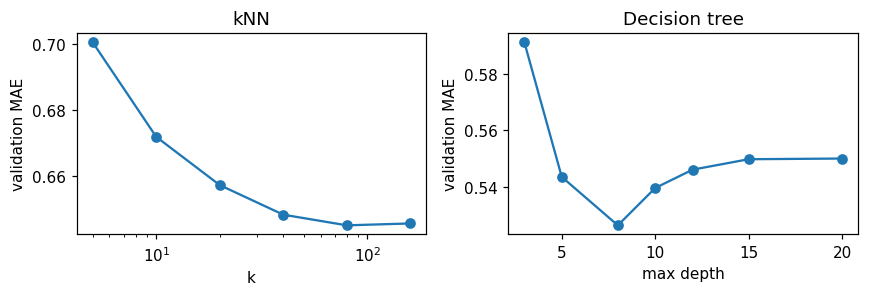

In [ ]:
plt.figure(figsize=(8, 2.8))

plt.subplot(1, 2, 1)
knn_rows = tuning[tuning['model'] == 'kNN']
plt.plot(knn_rows['value'], knn_rows['val_MAE'], marker='o')
plt.xscale('log')
plt.xlabel('k')
plt.ylabel('validation MAE')
plt.title('kNN')

plt.subplot(1, 2, 2)
tree_rows = tuning[tuning['model'] == 'Tree']
plt.plot(tree_rows['value'], tree_rows['val_MAE'], marker='o')
plt.xlabel('max depth')
plt.ylabel('validation MAE')
plt.title('Decision tree')

plt.tight_layout()
plt.show()

# kNN keeps getting better until about k=80, the tree starts overfitting after depth 8

In [ ]:
# C0 = the first linear regression from above (same features, same pipeline)
# C1-C3 use the day-ahead features
course_models = {
    'C0 Linear regression, team draft (no lags)': (linear_model, features),
    'C1 Linear regression, day-ahead features': (Pipeline([('scaler', StandardScaler()), ('regression', LinearRegression())]), features_day_ahead),
    f'C2 kNN, day-ahead features (k={best_k})': (Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor(n_neighbors=best_k, weights='distance'))]), features_day_ahead),
    f'C3 Decision tree, day-ahead features (depth={best_depth})': (Pipeline([('tree', DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=20, random_state=seed))]), features_day_ahead),
}

for name, (model, cols) in course_models.items():
  # validation: trained on 2022
  model_train = clone(model)
  model_train.fit(train_df[cols], train_df[target])
  val_predictions[name] = model_train.predict(val_df[cols])
  test_predictions_trainonly[name] = model_train.predict(test_df[cols])

  # test: retrained on 2022 + 2023
  model_trainval = clone(model)
  model_trainval.fit(trainval_df[cols], trainval_df[target])
  test_predictions[name] = model_trainval.predict(test_df[cols])

  print(name, ' val mae:', round(get_scores(y_val, val_predictions[name])['MAE'], 3))

C0 Linear regression, team draft (no lags)  val mae: 1.002
C1 Linear regression, day-ahead features  val mae: 0.506
C2 kNN, day-ahead features (k=80)  val mae: 0.645
C3 Decision tree, day-ahead features (depth=8)  val mae: 0.526


# Baseline Table
kWh per client per hour, lower is better. Winter is Dec to Feb and Event is hilo challenge hours

In [ ]:
# every model, every split, every slice in one long table
rows = []
for name in val_predictions:
  for split_name, part_df, predictions in [('val', val_df, val_predictions),
                                           ('test', test_df, test_predictions),
                                           ('test_trainonly', test_df, test_predictions_trainonly)]:
    for slice_name, scores in get_scores_by_slice(part_df, predictions[name]).items():
      rows.append({'model': name, 'split': split_name, 'slice': slice_name, **scores})

results = pd.DataFrame(rows)
results.to_csv(results_folder / 'metrics_long.csv', index=False)

# making sure C0 matches the first model exactly
c0_val = results[results['model'].str.startswith('C0') & (results['split'] == 'val') & (results['slice'] == 'all')].iloc[0]
print('C0 val mae:', round(c0_val['MAE'], 4), ' first model val mae:', round(mae, 4))

C0 val mae: 1.0023  first model val mae: 1.0023


In [ ]:
def pick(split_name, slice_name, cols):
  part = results[(results['split'] == split_name) & (results['slice'] == slice_name)].set_index('model')
  return part[cols]

# full table with every score, saved to results/ for the repo
baseline_table = pd.concat({
    'val': pick('val', 'all', ['MAE', 'RMSE', 'MAPE_%', 'R2']),
    'test': pick('test', 'all', ['MAE', 'RMSE', 'MAPE_%', 'R2']),
    'test winter': pick('test', 'winter', ['MAE', 'RMSE']),
    'test event hours': pick('test', 'event', ['MAE', 'bias']),
}, axis=1).round(3)
baseline_table.to_csv(results_folder / 'baseline_table.csv')

best_on_val = pick('val', 'all', ['MAE'])['MAE'].idxmin()
print('best on validation:', best_on_val)

# smaller table to read in the notebook: one header row, short names, just the main scores
short_names = {'N1': 'N1 same hour yesterday', 'N2': 'N2 same hour last week', 'N3': 'N3 average for that hour',
               'C0': 'C0 first LR (team draft)', 'C1': 'C1 LR with lags', 'C2': 'C2 kNN', 'C3': 'C3 decision tree'}

summary = pd.DataFrame({
    'val MAE (2023)': baseline_table[('val', 'MAE')],
    'test MAE (2024)': baseline_table[('test', 'MAE')],
    'test RMSE': baseline_table[('test', 'RMSE')],
    'test R2': baseline_table[('test', 'R2')],
    'winter MAE': baseline_table[('test winter', 'MAE')],
    'event MAE': baseline_table[('test event hours', 'MAE')],
    'event bias': baseline_table[('test event hours', 'bias')],
})
summary.index = [short_names[name[:2]] for name in summary.index]
summary.index.name = 'model'

# green + bold = best in that column (lowest error, highest R2), black text so its readable in dark mode
best = 'background-color: #d9ead3; color: black; font-weight: bold'
summary.style.format('{:.3f}') \
  .highlight_min(subset=['val MAE (2023)', 'test MAE (2024)', 'test RMSE', 'winter MAE', 'event MAE'], props=best) \
  .highlight_max(subset=['test R2'], props=best) \
  .set_table_styles([{'selector': 'th', 'props': 'text-align: center;'},
                     {'selector': 'th.row_heading', 'props': 'text-align: left;'}])

best on validation: C1 Linear regression, day-ahead features


,val MAE (2023),test MAE (2024),test RMSE,test R2,winter MAE,event MAE,event bias
model,,,,,,,
N1 same hour yesterday,0.533,0.368,0.579,0.683,0.609,0.998,0.785
N2 same hour last week,0.792,0.571,0.826,0.355,0.886,1.261,1.079
N3 average for that hour,1.379,1.372,1.574,-1.345,0.676,1.700,1.625
C0 first LR (team draft),1.002,1.568,1.800,-2.066,2.092,3.658,3.658
C1 LR with lags,0.506,0.402,0.531,0.733,0.606,0.801,-0.312
C2 kNN,0.645,0.597,0.798,0.397,0.926,1.301,1.292
C3 decision tree,0.526,0.466,0.757,0.458,0.863,1.422,1.300


C1 is our course-level baseline because its best on validation and on test it beats N1 on RMSE and event hours but not on overall MAE

In [ ]:

# this is just a check, not part of our baseline
# lag_1h = the hour right before, so this is like predicting 7pm when you already know 6pm
# copying the hour before gets mae 0.236, way better than all our day-ahead models (best on test was 0.368)
# adding C1's other features barely helps (0.226), the model is basically just copying lag_1h
# but we forecast tomorrow, so we wont know the hour before when we make the forecast
# thats why lag_1h, indoor temp and setpoint stay out of the model, using them would be kind of cheating

next_hour = []

# persistence = guess the hour before
next_hour.append({'model': 'Persistence y(t-1)', **get_scores(y_test, test_df['lag_1h'])})

c1_next_hour = Pipeline([('scaler', StandardScaler()), ('regression', LinearRegression())])
c1_next_hour.fit(trainval_df[features_day_ahead + ['lag_1h']], trainval_df[target])
next_hour.append({'model': 'C1 + lag_1h', **get_scores(y_test, c1_next_hour.predict(test_df[features_day_ahead + ['lag_1h']]))})

next_hour = pd.DataFrame(next_hour).round(3)
next_hour.to_csv(results_folder / 'next_hour_sensitivity.csv', index=False)
next_hour

,model,MAE,RMSE,MAPE_%,R2,bias,n
0,Persistence y(t-1),0.236,0.413,12.773,0.839,0.000,13101
1,C1 + lag_1h,0.226,0.334,12.678,0.895,0.067,13101


In [ ]:
# this checks what happens if we split randomly instead of by date
# random split: train on a random 80% of all hours (2022 to jun 2024) and test on the other 20%
# kNN goes from worst to best because the hours right next to each test hour are in training,
# so it just finds almost the same hour and copies it, basically memorizing and not predicting
# C0 gets better because it gets to see some 2024 hours in training, which it wouldnt have for a real forecast
# C1 gets worse because it has to fit hours from before and after the 29 nov 2023 drop together
# so a random split would make us pick kNN, which is actually the worst at predicting new months
# thats why we split by date: train on the past, test on the future

from sklearn.model_selection import train_test_split

# sorting first so the random split picks the same rows every run
all_rows = pd.concat([train_df, val_df, test_df]).sort_values(['timestamp_clean', 'substation_name'])
random_train, random_test = train_test_split(all_rows, test_size=0.2, random_state=seed)

random_vs_date = []
for name, (model, cols) in course_models.items():
  model_random = clone(model)
  model_random.fit(random_train[cols], random_train[target])
  random_mae = mean_absolute_error(random_test[target], model_random.predict(random_test[cols]))
  date_mae = get_scores(y_test, test_predictions[name])['MAE']
  random_vs_date.append({'model': name, 'test MAE, date split (Jan-Jun 2024)': date_mae, 'test MAE, random 80/20 split': random_mae})

random_vs_date = pd.DataFrame(random_vs_date).round(3)
random_vs_date.to_csv(results_folder / 'random_vs_date_split.csv', index=False)
random_vs_date

,model,"test MAE, date split (Jan-Jun 2024)","test MAE, random 80/20 split"
0,"C0 Linear regression, team draft (no lags)",1.568,1.030
1,"C1 Linear regression, day-ahead features",0.402,0.469
2,"C2 kNN, day-ahead features (k=80)",0.597,0.431
3,"C3 Decision tree, day-ahead features (depth=8)",0.466,0.436


# Discrepancy Analysis
C1 wins on validation (0.506 vs 0.533 for N1) but N1 wins on test MAE (0.368 vs 0.402) but why?

In [ ]:
# comparing jan-jun of each year
model_df['year'] = model_df['timestamp_clean'].dt.year
jan_to_jun = model_df[model_df['month'].between(1, 6)]

by_year = jan_to_jun.groupby(['year', 'substation_name']).agg(
    mean_kwh_per_client=('energy_per_client', 'mean'),
    mean_clients=('connected_clients', 'mean'),
    mean_outside_temp=('average_outside_temperature', 'mean')).round(2)
by_year.index.names = ['year', 'substation']
by_year.to_csv(results_folder / 'discrepancy_jan_jun_by_year.csv')
by_year

# same number of clients in 2023 and 2024 and 2024 was only a bit warmer, but energy per client is about half

mean_kwh_per_client  mean_clients  mean_outside_temp
year substation                                                      
2022 A                          3.89         24.72               2.47
     B                          4.11         13.73               2.47
     C                          3.95         55.24               2.47
2023 A                          3.37         51.57               4.38
     B                          4.29         38.32               4.38
     C                          3.76         99.83               4.38
2024 A                          1.79         52.36               5.97
     B                          2.16         37.50               5.97
     C                          1.88        102.48               5.97

In [ ]:
'''
want to find when the drop happened
for each day: actual energy / what the outdoor temperature alone says it should be
fitting a simple line (energy vs heating degrees) on oct 2022 to oct 2023
if the ratio is around 1 its a normal day for that weather
if all 3 substations drop on the same day its probably the data changing and not the weather
'''
daily_ratio = model_df.groupby(['substation_name', 'date']).agg(
    energy=('energy_per_client', 'mean'),
    temp=('average_outside_temperature', 'mean')).reset_index()
daily_ratio['date'] = pd.to_datetime(daily_ratio['date'])
daily_ratio['heating_degrees'] = np.maximum(0, 18 - daily_ratio['temp'])

fit_days = daily_ratio[(daily_ratio['date'] >= '2022-10-01') & (daily_ratio['date'] < '2023-11-01')]
x = np.column_stack([np.ones(len(fit_days)), fit_days['heating_degrees']])
intercept, slope = np.linalg.lstsq(x, fit_days['energy'], rcond=None)[0]

daily_ratio['ratio'] = daily_ratio['energy'] / (intercept + slope * daily_ratio['heating_degrees'])

# looking at the days around where it drops
around = daily_ratio[(daily_ratio['date'] >= '2023-11-24') & (daily_ratio['date'] <= '2023-12-03')]
around.pivot(index='date', columns='substation_name', values='ratio').round(2)

# all three drop to about 0.55-0.65 on nov 29 and stay there

substation_name,A,B,C
date,,,
2023-11-24,0.78,0.99,0.89
2023-11-25,0.93,1.22,1.03
2023-11-26,0.99,1.19,1.04
2023-11-27,0.91,1.08,1.01
2023-11-28,0.75,0.87,0.80
2023-11-29,0.54,0.63,0.56
2023-11-30,0.53,0.65,0.58
2023-12-01,0.49,0.60,0.54
2023-12-02,0.47,0.57,0.50


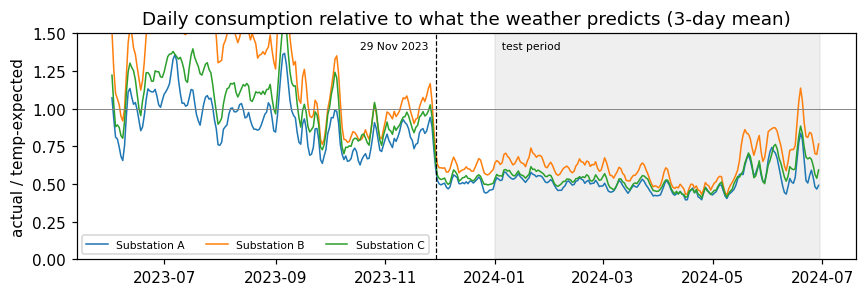

share of train + val rows after the drop: 4.6 %
share of test rows after the drop: 100 %


In [ ]:
level_shift_date = '2023-11-29'
shown = daily_ratio[daily_ratio['date'] >= '2023-06-01']

plt.figure(figsize=(8, 2.8))
for station in ['A', 'B', 'C']:
  station_days = shown[shown['substation_name'] == station]
  plt.plot(station_days['date'], station_days['ratio'].rolling(3, center=True).mean(), linewidth=1, label=f'Substation {station}')

# dashed line = the drop, grey = test period
plt.axvline(pd.Timestamp(level_shift_date), color='black', linestyle='--', linewidth=0.8)
plt.axvspan(pd.Timestamp('2024-01-01'), shown['date'].max(), color='grey', alpha=0.12)
plt.axhline(1, color='grey', linewidth=0.6)
plt.text(pd.Timestamp('2024-01-01'), 1.45, '  test period', fontsize=7, va='top')
plt.text(pd.Timestamp(level_shift_date), 1.45, '29 Nov 2023  ', fontsize=7, va='top', ha='right')

plt.ylim(0, 1.5)
plt.ylabel('actual / temp-expected')
plt.title('Daily consumption relative to what the weather predicts (3-day mean)')
plt.legend(fontsize=7, ncol=3, loc='lower left')
plt.tight_layout()
plt.savefig(results_folder / 'fig_level_shift.png')
plt.show()

shift_time = pd.Timestamp(level_shift_date, tz='America/Montreal')
print('share of train + val rows after the drop:', round((trainval_df['timestamp_clean'] >= shift_time).mean() * 100, 1), '%')
print('share of test rows after the drop:', round((test_df['timestamp_clean'] >= shift_time).mean() * 100), '%')

# client and thermostat counts dont change that day, so probably a metering change, not people using less

In [ ]:
# validation (2023) has hours before and after the drop, so can compare directly
n1 = 'N1 Seasonal naive, same hour yesterday'
c1 = 'C1 Linear regression, day-ahead features'
c0 = 'C0 Linear regression, team draft (no lags)'

before_after = []
for split_name, part_df, predictions in [('val', val_df, val_predictions), ('test', test_df, test_predictions)]:
  for period in ['before shift', 'after shift']:
    if period == 'before shift':
      mask = (part_df['timestamp_clean'] < shift_time).to_numpy()
    else:
      mask = (part_df['timestamp_clean'] >= shift_time).to_numpy()
    if mask.sum() == 0:
      continue
    for name in [n1, c1, c0]:
      scores = get_scores(part_df[target].to_numpy()[mask], predictions[name][mask])
      before_after.append({'split': split_name, 'period': period, 'model': name[:2],
                           'MAE': scores['MAE'], 'bias': scores['bias'], 'n': scores['n']})

before_after = pd.DataFrame(before_after).round(3)
before_after.to_csv(results_folder / 'discrepancy_before_after_shift.csv', index=False)
before_after


# before the drop C1 beats N1, after it C1 guesses too high
# C1 learned how much energy goes up when its cold from data before the drop
# N1 just copies yesterday so it adjusts right away
# the whole test set is after the drop so N1 wins on test mae
# models with no lags (C0, climatology) cant adjust at all, so C0 goes from 1.00 on val to 1.57 on test

,split,period,model,MAE,bias,n
0,val,before shift,N1,0.539,-0.002,23904
1,val,before shift,C1,0.474,-0.116,23904
2,val,before shift,C0,0.873,-0.140,23904
3,val,after shift,N1,0.475,0.035,2376
4,val,after shift,C1,0.821,0.800,2376
5,val,after shift,C0,2.303,2.303,2376
6,test,after shift,N1,0.368,0.010,13101
7,test,after shift,C1,0.402,0.220,13101
8,test,after shift,C0,1.568,1.471,13101


In [ ]:
# where the errors are in the test set
errors = test_df[['timestamp_clean', 'hour', 'substation_name', 'challenge_flag', target]].copy()
errors['pred_C0'] = test_predictions[c0]
errors['pred_C1'] = test_predictions[c1]
errors['pred_N1'] = test_predictions[n1]
errors['abs_err_C0'] = (errors['pred_C0'] - errors[target]).abs()
errors['abs_err_C1'] = (errors['pred_C1'] - errors[target]).abs()
errors['abs_err_N1'] = (errors['pred_N1'] - errors[target]).abs()

by_month = errors.groupby(errors['timestamp_clean'].dt.month)[['abs_err_C0', 'abs_err_C1', 'abs_err_N1']].mean().round(3)
by_month.index.name = 'month (2024)'
by_month.to_csv(results_folder / 'discrepancy_mae_by_month_test.csv')
by_month

,abs_err_C0,abs_err_C1,abs_err_N1
month (2024),,,
1,2.063,0.588,0.534
2,2.122,0.625,0.689
3,1.919,0.381,0.377
4,1.750,0.304,0.280
5,0.904,0.281,0.173
6,0.665,0.238,0.167


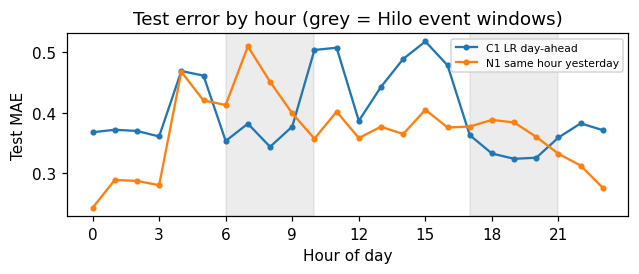

In [ ]:
by_hour = errors.groupby('hour')[['abs_err_C1', 'abs_err_N1']].mean()

plt.figure(figsize=(6, 2.6))
plt.plot(by_hour.index, by_hour['abs_err_C1'], marker='o', markersize=3, label='C1 LR day-ahead')
plt.plot(by_hour.index, by_hour['abs_err_N1'], marker='o', markersize=3, label='N1 same hour yesterday')

# shading the hilo event windows like in m2
plt.axvspan(6, 10, alpha=0.15, color='gray')
plt.axvspan(17, 21, alpha=0.15, color='gray')

plt.xticks(range(0, 24, 3))
plt.xlabel('Hour of day')
plt.ylabel('Test MAE')
plt.title('Test error by hour (grey = Hilo event windows)')
plt.legend(fontsize=7)
plt.tight_layout()
plt.savefig(results_folder / 'fig_error_by_hour.png')
plt.show()

# N1 is worst in the morning event window (7-8am), C1 does better there and in the evening one
# C1 is worst from about 10am to 4pm

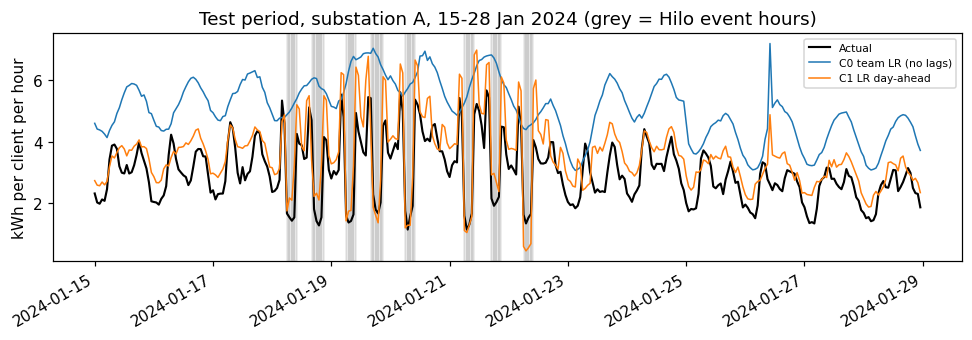

In [ ]:
# two winter weeks of the test set, substation A
two_weeks = errors[(errors['substation_name'] == 'A') &
                   (errors['timestamp_clean'] >= pd.Timestamp('2024-01-15', tz='America/Montreal')) &
                   (errors['timestamp_clean'] < pd.Timestamp('2024-01-29', tz='America/Montreal'))]

plt.figure(figsize=(9, 3.2))
plt.plot(two_weeks['timestamp_clean'], two_weeks[target], color='black', linewidth=1.4, label='Actual')
plt.plot(two_weeks['timestamp_clean'], two_weeks['pred_C0'], linewidth=1, label='C0 team LR (no lags)')
plt.plot(two_weeks['timestamp_clean'], two_weeks['pred_C1'], linewidth=1, label='C1 LR day-ahead')

# grey = hilo event hours
for event_hour in two_weeks[two_weeks['challenge_flag'] == 1]['timestamp_clean']:
  plt.axvspan(event_hour, event_hour + pd.Timedelta(hours=1), color='grey', alpha=0.18)

plt.ylabel('kWh per client per hour')
plt.title('Test period, substation A, 15-28 Jan 2024 (grey = Hilo event hours)')
plt.legend(loc='upper right', fontsize=7)
plt.gcf().autofmt_xdate()
plt.tight_layout()
plt.savefig(results_folder / 'fig_test_two_weeks.png')
plt.show()

# C0 sits way above the actual line the whole time (no lags, still at the old level)
# C1 follows the level but the day after an event its 24h lag repeats yesterday's dip and rebound

In [ ]:
log_lags = ['lag_24h', 'lag_168h', 'lag_24h_mean_day']

def log_features(part_df):
  x = part_df[features_day_ahead].copy()
  x[log_lags] = np.log(x[log_lags])
  return x

log_model = Pipeline([('scaler', StandardScaler()), ('regression', LinearRegression())])

# validation: trained on 2022
log_model.fit(log_features(train_df), np.log(train_df[target]))
log_val_scores = get_scores(y_val, np.exp(log_model.predict(log_features(val_df))))

# test: retrained on 2022 + 2023
log_model.fit(log_features(trainval_df), np.log(trainval_df[target]))
log_test_scores = get_scores(y_test, np.exp(log_model.predict(log_features(test_df))))

log_target = pd.DataFrame([{'split': 'val', **log_val_scores}, {'split': 'test', **log_test_scores}]).round(3)
log_target.to_csv(results_folder / 'diagnostic_log_target.csv', index=False)
log_target

# beats both C1 and N1 on val and test, so this is where m4 starts

,split,MAE,RMSE,MAPE_%,R2,bias,n
0,val,0.445,0.687,14.486,0.853,-0.119,26280
1,test,0.289,0.417,15.903,0.835,0.059,13101
